# Deliverable 5: Finding Groups of Trees, K-Means Clustering

**MOD10 Introduction to Machine Learning**, November 2026

- **Group:** CUPILLARD Eliot, DENOUAL Romain, ROY-NOUGUIER Erwann
- **Dataset:** Arbres publics sur le territoire de la Ville (consolidated file), City of Montreal, licence CC BY 4.0, same unchanged copy as Deliverable 2 (https://doi.org/10.5281/zenodo.23540888)
- **Label set aside:** `DHP`, the trunk diameter at 1.4 m (our target in Deliverables 3 and 4)
- **Question:** Are there natural groups of public trees, and do these groups have different trunk diameters?

## 0. Setup and data from Deliverable 2

We reuse the data saved at the end of Deliverable 2 (`data/processed/trees_encoded.csv`): cleaned and encoded, not scaled. We do not clean or encode again.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 42
DATA_PATH = Path("../data/processed/trees_encoded.csv")

assert DATA_PATH.is_file(), "File missing: run Deliverable 2 with the to_csv line of section 3 not commented"
data = pd.read_csv(DATA_PATH, index_col="raw_row")
assert data.shape == (334950, 62), "Wrong shape: this is not the file of Deliverable 2"

print("Data:", data.shape, "| Missing values:", data.isna().sum().sum())

Data: (334950, 62) | Missing values: 0


## 1. Features only

`DHP` is our label, so we set it aside. We use it again in section 5.

There is no ID column: `raw_row` is the index.

We start with all 61 features of Deliverable 2. Only `Latitude`, `Longitude` and `age` are real numbers. The 58 other columns are 0/1 (borough, species, place, street or park...).

Section 3.1 shows that this does not work well, so section 3.2 keeps only four columns.

In [2]:
print("data before drop:", data.shape)
X = data.drop(columns=["DHP"])
print("X after drop:", X.shape)

data before drop: (334950, 62)
X after drop: (334950, 61)


## 2. Scale

K-Means uses distances, like KNN, so we scale the features.

We do not predict anything, so there is no train/test split. We fit the scaler on all the trees.

Rare 0/1 columns get big values after scaling. `Arbre_remarquable` (157 trees) goes up to 46.

In [3]:
X_s = StandardScaler().fit_transform(X)

## 3. Choose k: the elbow

Inertia measures how far the trees are from the centre of their cluster. Lower is better, but it always goes down when k goes up.

So we look for the elbow: the point where the curve starts to go down slower. We try k = 2 to 8.

### 3.1 First try: all 61 features

k=2 | inertia=19773441


k=3 | inertia=19217857


k=4 | inertia=18744959


k=5 | inertia=18494045


k=6 | inertia=17874004


k=7 | inertia=17621555


k=8 | inertia=17280287


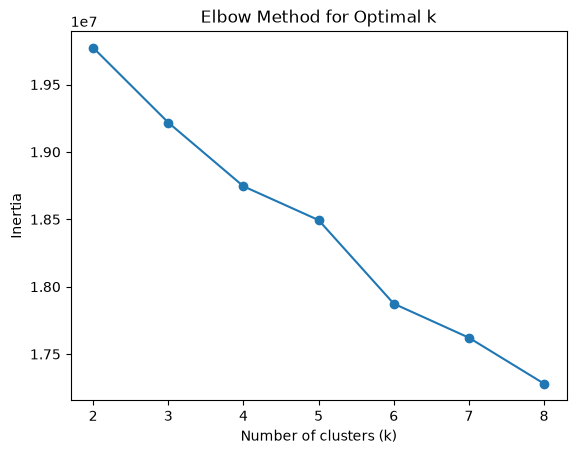

In [4]:
k_values = range(2, 9)
inertia_values = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_s)
    inertia_values.append(kmeans.inertia_)
    print(f"k={k} | inertia={kmeans.inertia_:.0f}")

plt.plot(k_values, inertia_values, marker="o")
plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.show()

There is no clear elbow. The curve goes down almost in a straight line, from 19.77 M (k=2) to 17.28 M (k=8).

With one cluster, the inertia would be 20.43 M (61 columns × 334,950 trees). So 8 clusters only remove 15% of it.

The problem is the 58 columns of 0/1. Each new cluster just splits one more category, like a borough or a species. There are no real groups in these columns.

Maybe the elbow comes later, with many more clusters. We check it with k = 10 to 70.

k=10 | inertia=16618682


k=20 | inertia=13349995


k=30 | inertia=10479571


k=40 | inertia=8244773


k=50 | inertia=6455157


k=60 | inertia=5880677


k=70 | inertia=5586576


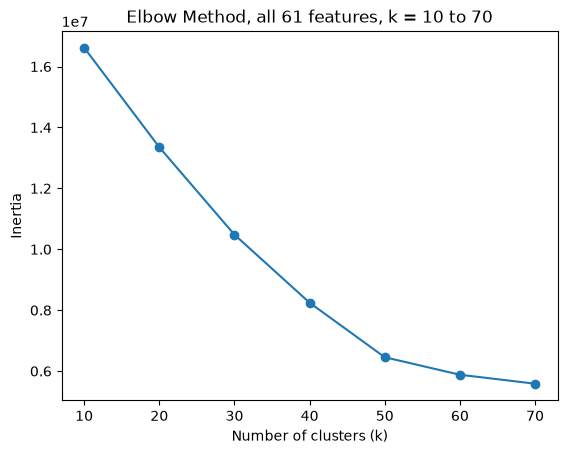

In [5]:
k_large = range(10, 71, 10)
inertia_large = []
for k in k_large:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_s)
    inertia_large.append(kmeans.inertia_)
    print(f"k={k} | inertia={kmeans.inertia_:.0f}")

plt.plot(k_large, inertia_large, marker="o")
plt.title("Elbow Method, all 61 features, k = 10 to 70")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.show()

This time there is a bend, at about k = 50. Up to k = 50, each 10 more clusters remove 1.8 M to 3.3 M. After k = 50, they only remove 0.57 M, then 0.29 M. We also ran every k from 2 to 69 once (too slow to keep here), and the curve has the same shape.

50 is close to the number of 0/1 columns (58). So K-Means probably puts about one category in each cluster, like one species or one borough. We did not check it cluster by cluster.

We do not keep this k. We already know these categories, and we cannot describe 50 groups in simple words. So we try again with fewer columns.

### 3.2 Second try: four columns

We keep:

- `Latitude` and `Longitude`: where the tree is (this already gives the borough)
- `age`
- `INV_TYPE`: street tree or park tree

We drop the species and place columns.

Limit: in Deliverable 2, 40% of the ages were unknown and set to 3. Most of these trees are big, but K-Means sees them as young.

We also compute the silhouette score, as a second opinion on k. It goes from −1 to 1: the higher it is, the better the groups are separated. It compares each tree with all the others, which is too slow for 334,950 trees, so we compute it on 10,000 random trees (`sample_size`).

X_small: (334950, 4)


k=2 | inertia=980948 | silhouette=0.335


k=3 | inertia=732182 | silhouette=0.386


k=4 | inertia=541866 | silhouette=0.418


k=5 | inertia=425705 | silhouette=0.414


k=6 | inertia=352053 | silhouette=0.369


k=7 | inertia=306258 | silhouette=0.369


k=8 | inertia=275439 | silhouette=0.368


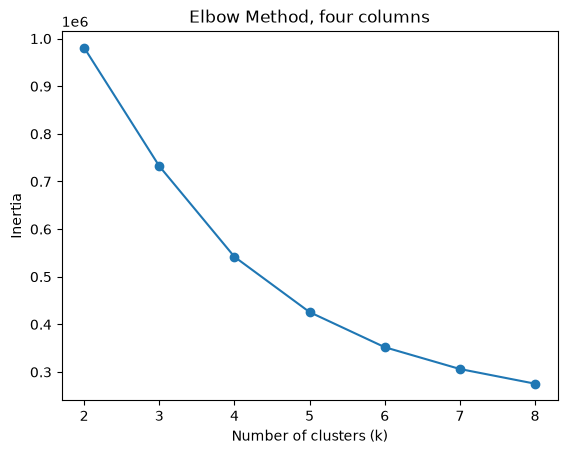

In [6]:
columns = ["Latitude", "Longitude", "age", "INV_TYPE"]
X_small = data[columns]
X_small_s = StandardScaler().fit_transform(X_small)
print("X_small:", X_small.shape)

inertia_small = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    clusters = kmeans.fit_predict(X_small_s)
    inertia_small.append(kmeans.inertia_)
    silhouette = silhouette_score(X_small_s, clusters, sample_size=10000, random_state=SEED)
    print(f"k={k} | inertia={kmeans.inertia_:.0f} | silhouette={silhouette:.3f}")

plt.plot(k_values, inertia_small, marker="o")
plt.title("Elbow Method, four columns")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.show()

This time the curve bends. It goes down fast until k=4, then slower.

From k=3 to k=4, the inertia drops by 0.19 M. From k=4 to k=5, only by 0.12 M, then 0.07 M.

The silhouette score agrees. It is highest at k=4 (0.418), and k=5 is very close (0.414). With another sample of 10,000 trees, the scores change by less than 0.01.

The bend is smooth, so it is a judgement call. We choose k = 4: it has the best silhouette, and fewer groups are easier to describe. With 4 clusters, the inertia goes from 1.34 M to 0.54 M (60% less).

## 4. Fit K-Means

We fit K-Means with k = 4 on the four scaled columns, with the same settings as in section 3 (`n_init=10`, `random_state=SEED`). `fit_predict` gives the cluster of each tree.

Trees per cluster: [157732 104620  44413  28185]


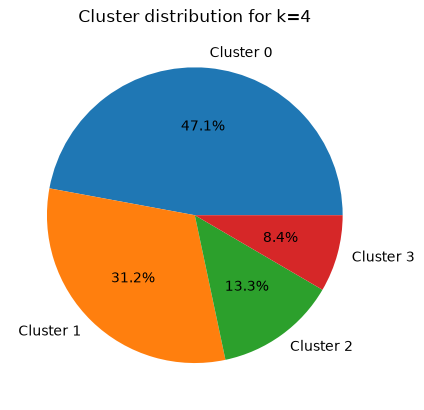

In [7]:
best_k = 4
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=SEED)
clusters = kmeans.fit_predict(X_small_s)
print("Trees per cluster:", np.bincount(clusters))

plt.title(f"Cluster distribution for k={best_k}")
plt.pie(np.bincount(clusters), labels=[f"Cluster {k}" for k in range(best_k)], autopct="%1.1f%%")
plt.show()

The groups have very different sizes: 157,732, 104,620, 44,413 and 28,185 trees (47.1%, 31.2%, 13.3% and 8.4%).

## 5. Profile the clusters

We add the cluster to the data and compute the mean of each column per cluster: the four columns used by K-Means, `age_missing`, and `DHP`, the label we set aside.

The mean of a 0/1 column is a share. For example, `INV_TYPE` = 0.59 means 59% of street trees.

In [8]:
prof = data.copy()
prof["cluster"] = clusters
prof.groupby("cluster")[columns + ["age_missing", "DHP"]].mean().round(2)

,Latitude,Longitude,age,INV_TYPE,age_missing,DHP
cluster,,,,,,
0,45.54,-73.59,3.57,1.00,0.37,21.34
1,45.55,-73.58,3.08,0.00,0.65,23.67
2,45.55,-73.59,38.41,0.99,0.00,44.04
3,45.48,-73.80,3.78,0.59,0.28,23.25


The mean `Latitude` and `Longitude` are hard to read, so we also look at the share of each borough in each cluster.

In [9]:
borough_columns = [c for c in data.columns if c.startswith("ARROND_NOM_")]
prof.groupby("cluster")[borough_columns].mean().round(2).T

cluster,0,1,2,3
ARROND_NOM_Ahuntsic - Cartierville,0.12,0.10,0.10,0.10
ARROND_NOM_Côte-des-Neiges - Notre-Dame-de-Grâce,0.12,0.05,0.09,0.00
ARROND_NOM_Lachine,0.00,0.00,0.00,0.28
ARROND_NOM_Le Plateau-Mont-Royal,0.06,0.06,0.09,0.00
ARROND_NOM_Le Sud-Ouest,0.06,0.10,0.07,0.00
ARROND_NOM_Mercier - Hochelaga-Maisonneuve,0.12,0.12,0.16,0.00
ARROND_NOM_Pierrefonds - Roxboro,0.00,0.00,0.00,0.61
ARROND_NOM_Rivière-des-Prairies - Pointe-aux-Trembles,0.10,0.14,0.11,0.00
ARROND_NOM_Rosemont - La Petite-Patrie,0.12,0.13,0.11,0.00
ARROND_NOM_Saint-Léonard,0.05,0.09,0.14,0.00


We also draw the clusters on a map. To keep it readable, we use 20,000 random trees: all of them in grey, and the trees of one cluster in colour.

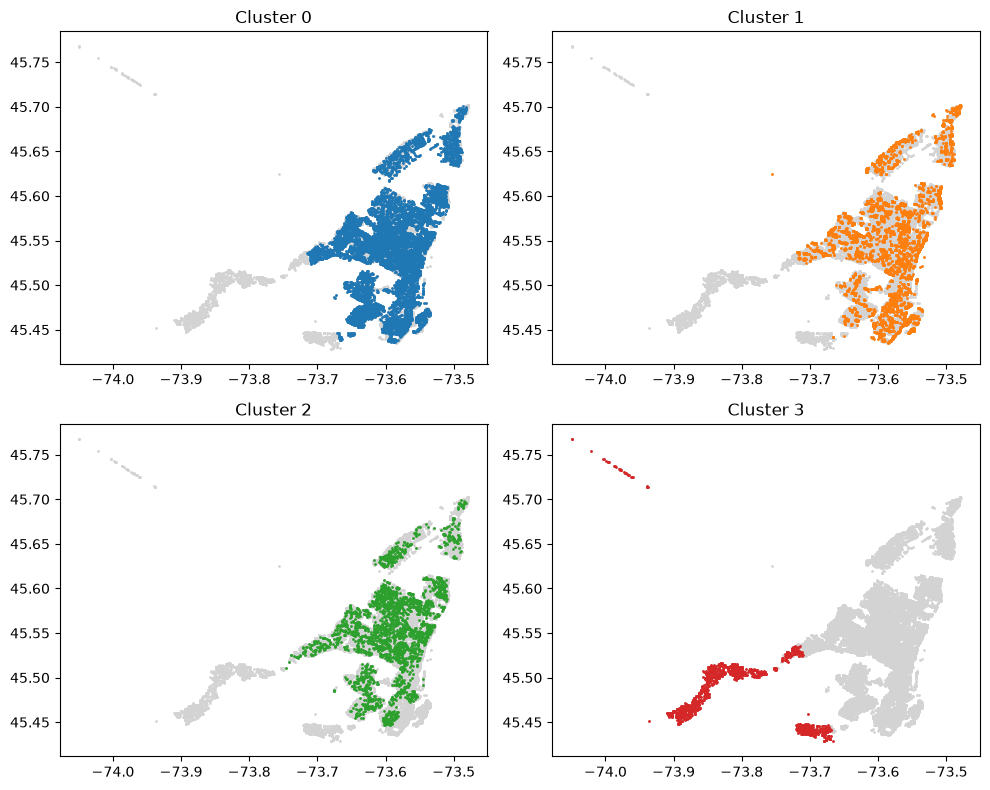

In [10]:
sample = prof.sample(20000, random_state=SEED)
plt.figure(figsize=(10, 8))
for k in range(best_k):
    group = sample[sample["cluster"] == k]
    plt.subplot(2, 2, k + 1)
    plt.scatter(sample["Longitude"], sample["Latitude"], s=1, color="lightgrey")
    plt.scatter(group["Longitude"], group["Latitude"], s=1, color=f"C{k}")
    plt.title(f"Cluster {k}")
plt.tight_layout()
plt.show()

In section 3.2, we saw that unknown ages were set to 3. So we compare the mean DHP of the trees with a known age (`age_missing` = 0) and with an unknown age (`age_missing` = 1), in each cluster.

In [11]:
prof.groupby(["cluster", "age_missing"])["DHP"].mean().round(1)

cluster  age_missing
0        0               8.9
         1              42.4
1        0               8.7
         1              31.8
2        0              44.0
3        0              20.4
         1              30.7
Name: DHP, dtype: float64

The mean DHP of each cluster. The red line is the mean of all the trees.

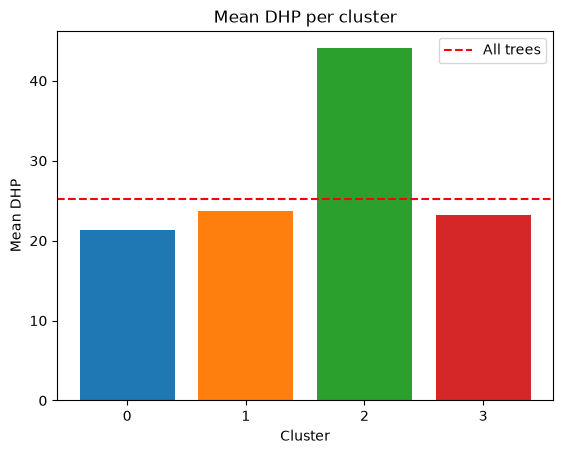

In [12]:
dhp_means = prof.groupby("cluster")["DHP"].mean()
plt.bar(dhp_means.index, dhp_means, color=["C0", "C1", "C2", "C3"])
plt.axhline(data["DHP"].mean(), color="red", linestyle="--", label="All trees")
plt.title("Mean DHP per cluster")
plt.xlabel("Cluster")
plt.ylabel("Mean DHP")
plt.xticks(range(best_k))
plt.legend()
plt.show()

- Cluster 2 has the old street trees: 38 years old on average, all with a known age. Their mean DHP is 44.0, about twice the other clusters.
- Clusters 0 and 1 split the street trees and the park trees. Both look young (age about 3), but many ages are unknown: 37% in cluster 0, 65% in cluster 1.
- Cluster 3 is the west of the island: 61% of its trees are in Pierrefonds-Roxboro and 28% in Lachine.
- On the map, clusters 0, 1 and 2 cover the same part of the city. Only cluster 3 is about the place.
- Clusters 0, 1 and 3 have close mean DHP (21.3 to 23.7). In these clusters, the trees with an unknown age are much bigger. In cluster 0, the mean DHP is 8.9 with a known age and 42.4 without.
- 428 trees of cluster 3 are about 40 km north-west of downtown, but the data puts them in Ville-Marie. Their position is probably wrong. Deliverable 2 kept them because they are inside our box around Montreal.

## 6. Describe each group

- Cluster 0, young street trees (47% of the trees): street trees planted a few years ago, everywhere except the west. Mean DHP 21.3. About one third have no planting date, and these ones are much bigger.
- Cluster 1, park trees (31%): almost all the park trees outside the west. Most of them (65%) have no planting date, so we do not really know their age. Mean DHP 23.7.
- Cluster 2, old street trees (13%): street trees about 38 years old (at least 19). They have the biggest trunks, with a mean DHP of 44.0.
- Cluster 3, trees of the west (8%): street and park trees of Pierrefonds-Roxboro and Lachine. Mean DHP 23.3.

## 7. Model fit

K-Means finds four groups, but they mostly follow what we already know: street or park, the age, and the west of the island. Only one group, the old street trees, has clearly bigger trunks. The unknown ages also blur the other groups.

So clustering helps to explore the data, but it does not help much to predict the trunk diameter. The regression of Deliverable 4 stays our main model.

For us, K-Means splits the trees into young street trees, park trees, old street trees and trees of the west, and only the old street trees have clearly bigger trunks (mean DHP 44 against 21 to 24).